In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Unzip once per session into local Colab storage (-q hides the 130-file printout)
!unzip -q "/content/drive/MyDrive/DronePropA Motion Trajectories Dataset.zip" -d /content/drone_data

Mounted at /content/drive


Using device: cuda
Loaded 130 files | Class counts [F0, F1, F2, F3]: [40 30 30 30]

########################################################################
OUTER FOLD 1/5 | Dev: 104 files [32 24 24 24] | Test: 26 files [8 6 6 6]
########################################################################

  [Outer 1 | Inner 1/5 | Run 1/25] Train: 83 files [25 19 20 19] | Val: 21 files [7 5 4 5]
    -> Best Val Loss: 0.4064 | Best Val Acc: 83.08% | Outer Test Acc: 80.87%

  [Outer 1 | Inner 2/5 | Run 2/25] Train: 83 files [25 20 19 19] | Val: 21 files [7 4 5 5]
    -> Best Val Loss: 0.4412 | Best Val Acc: 81.74% | Outer Test Acc: 83.33%

  [Outer 1 | Inner 3/5 | Run 3/25] Train: 83 files [26 19 19 19] | Val: 21 files [6 5 5 5]
    -> Best Val Loss: 0.3745 | Best Val Acc: 85.74% | Outer Test Acc: 78.77%

  [Outer 1 | Inner 4/5 | Run 4/25] Train: 83 files [26 19 19 19] | Val: 21 files [6 5 5 5]
    -> Best Val Loss: 0.5958 | Best Val Acc: 75.48% | Outer Test Acc: 80.31%

  [Outer 1 | Inner 5

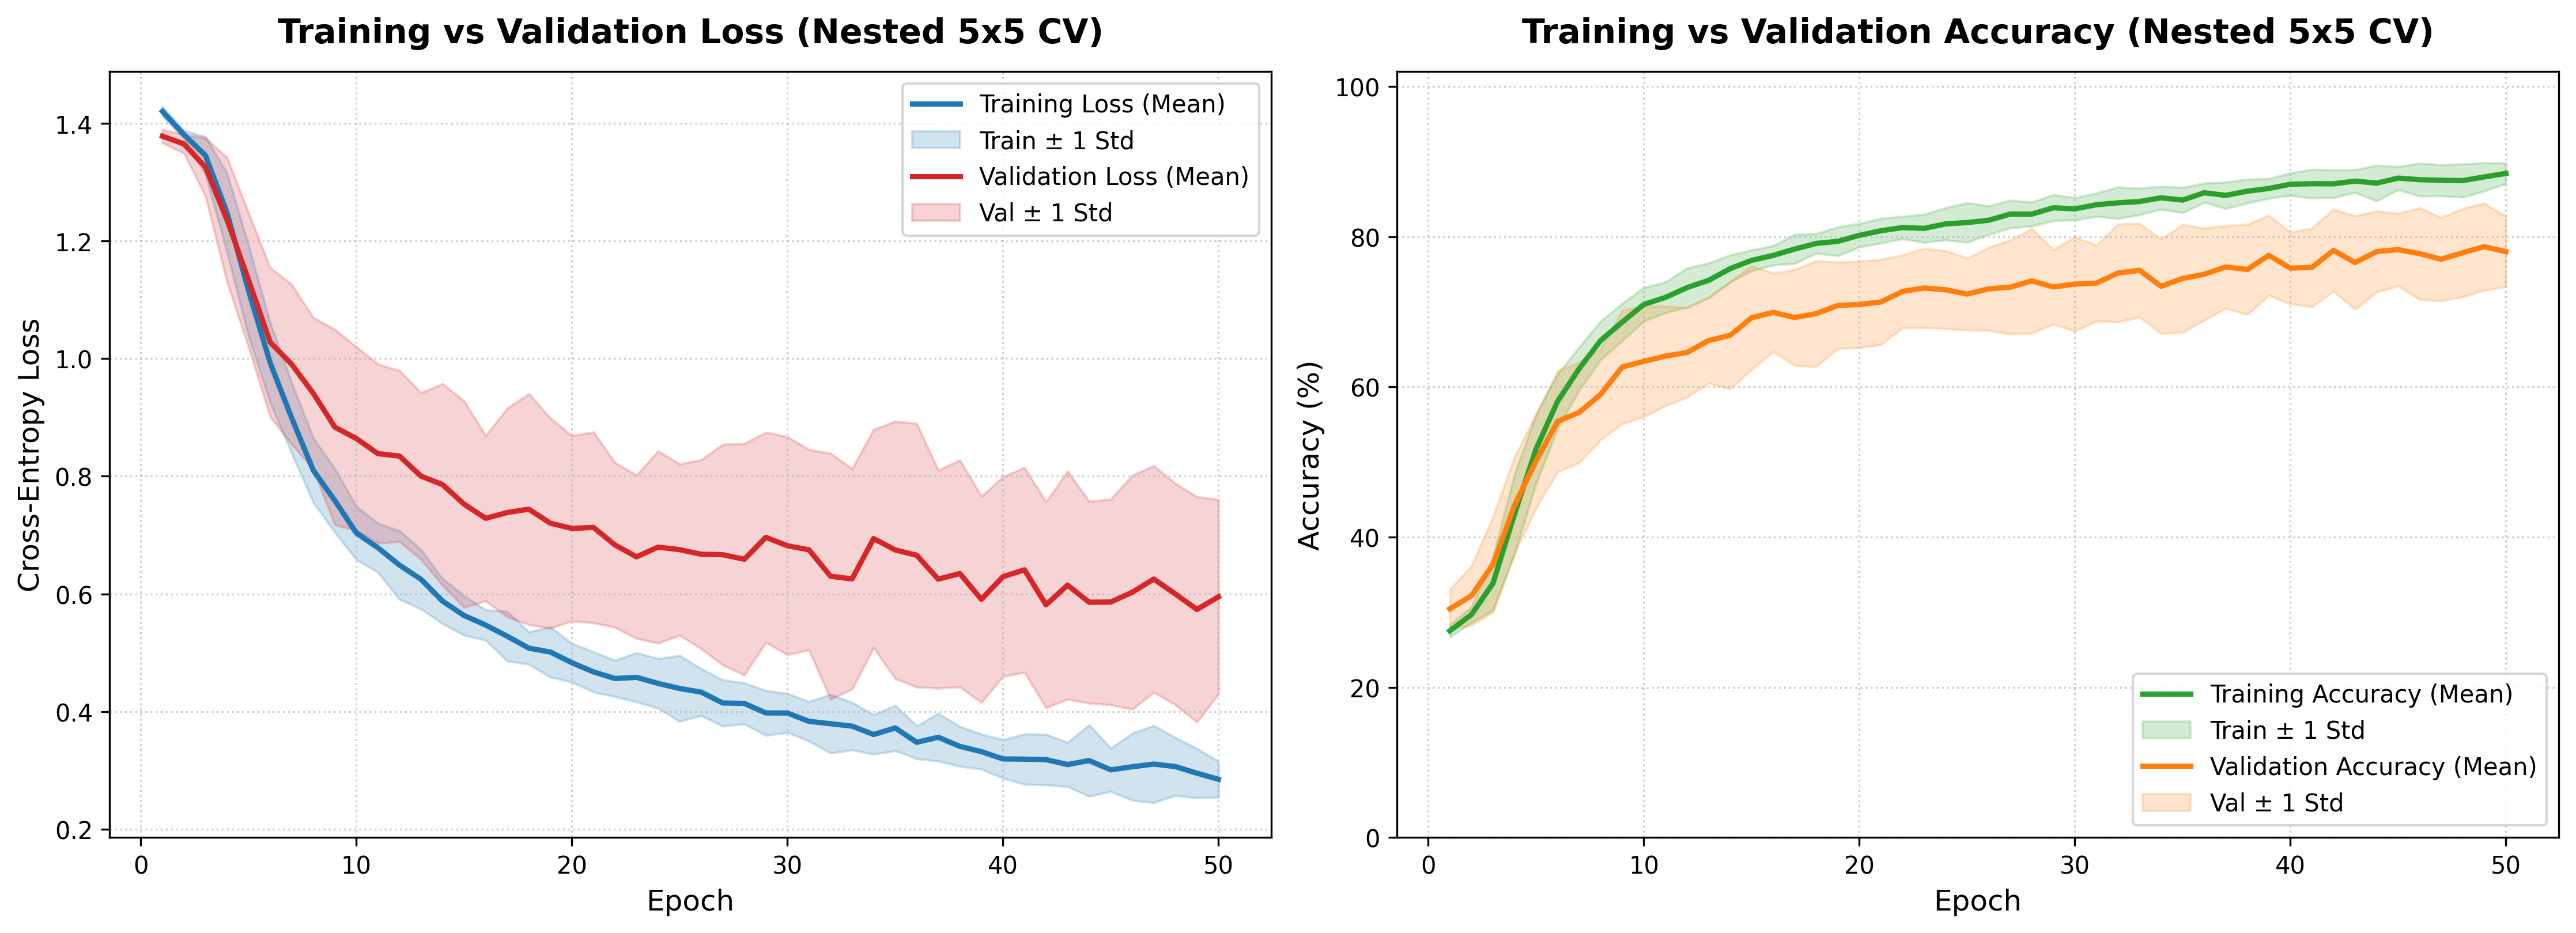

Saved confusion matrix to: nested_cv_confusion_matrix.png


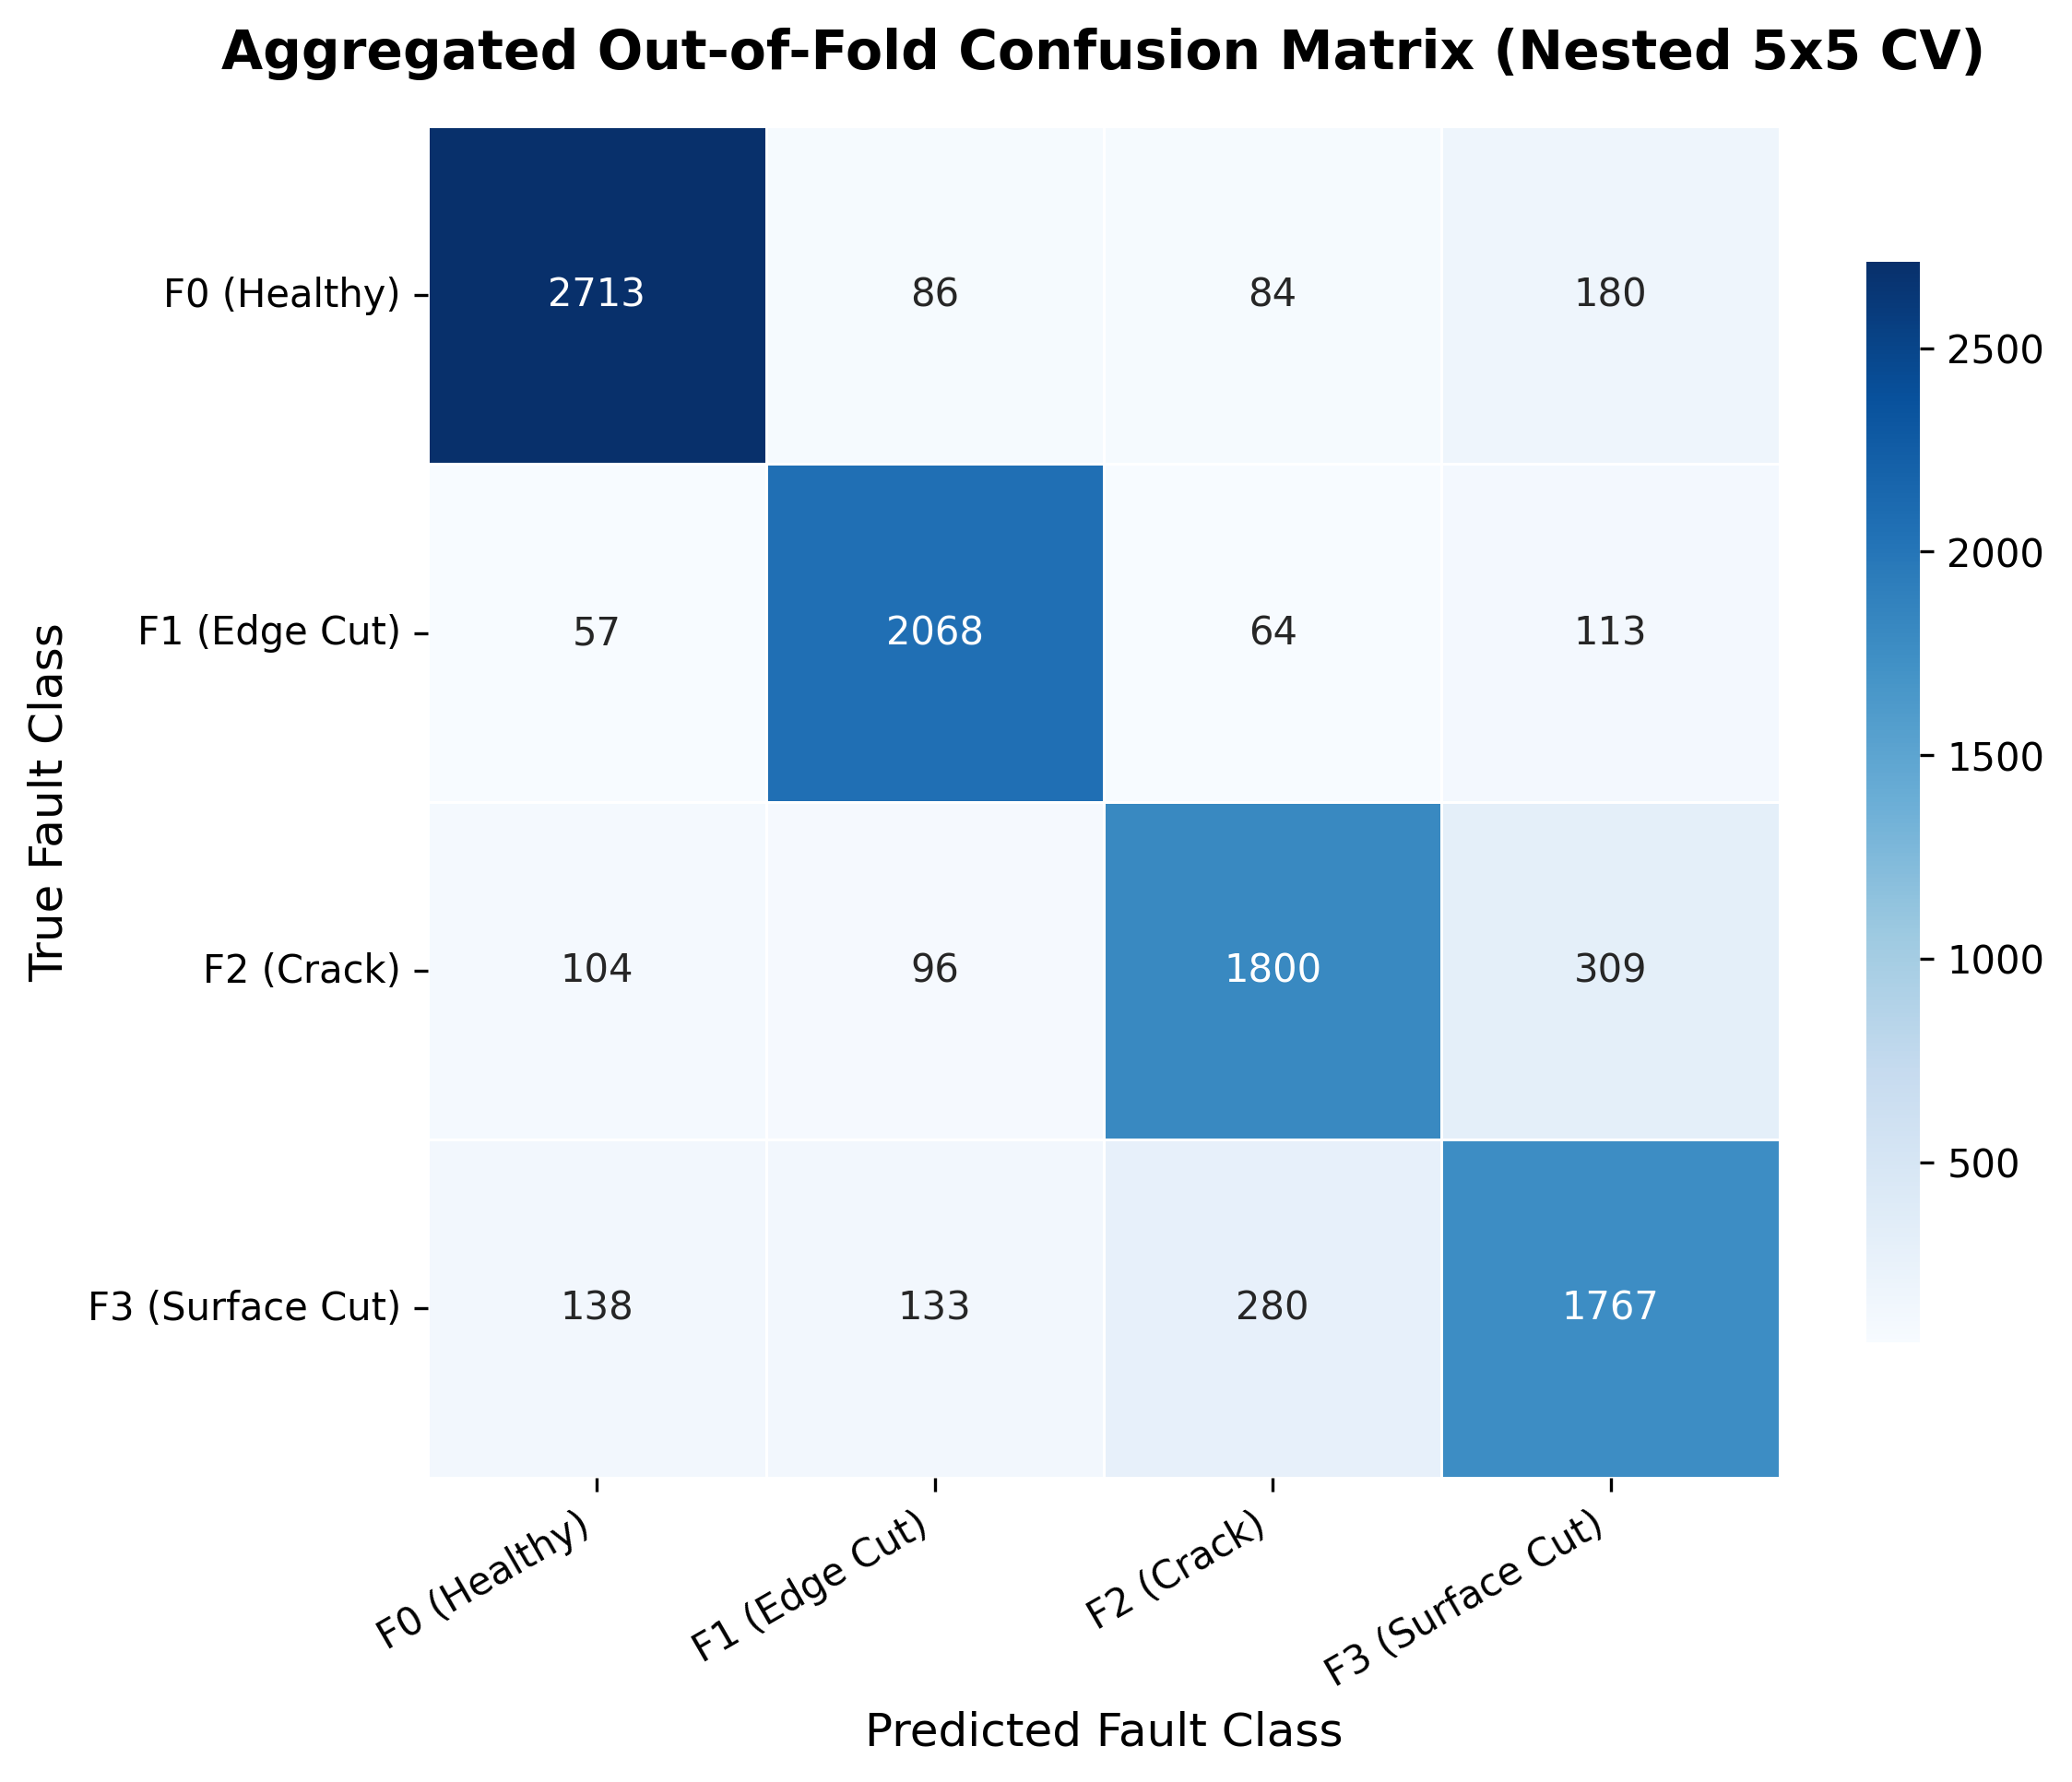

Saved classification report to: nested_cv_classification_report.png


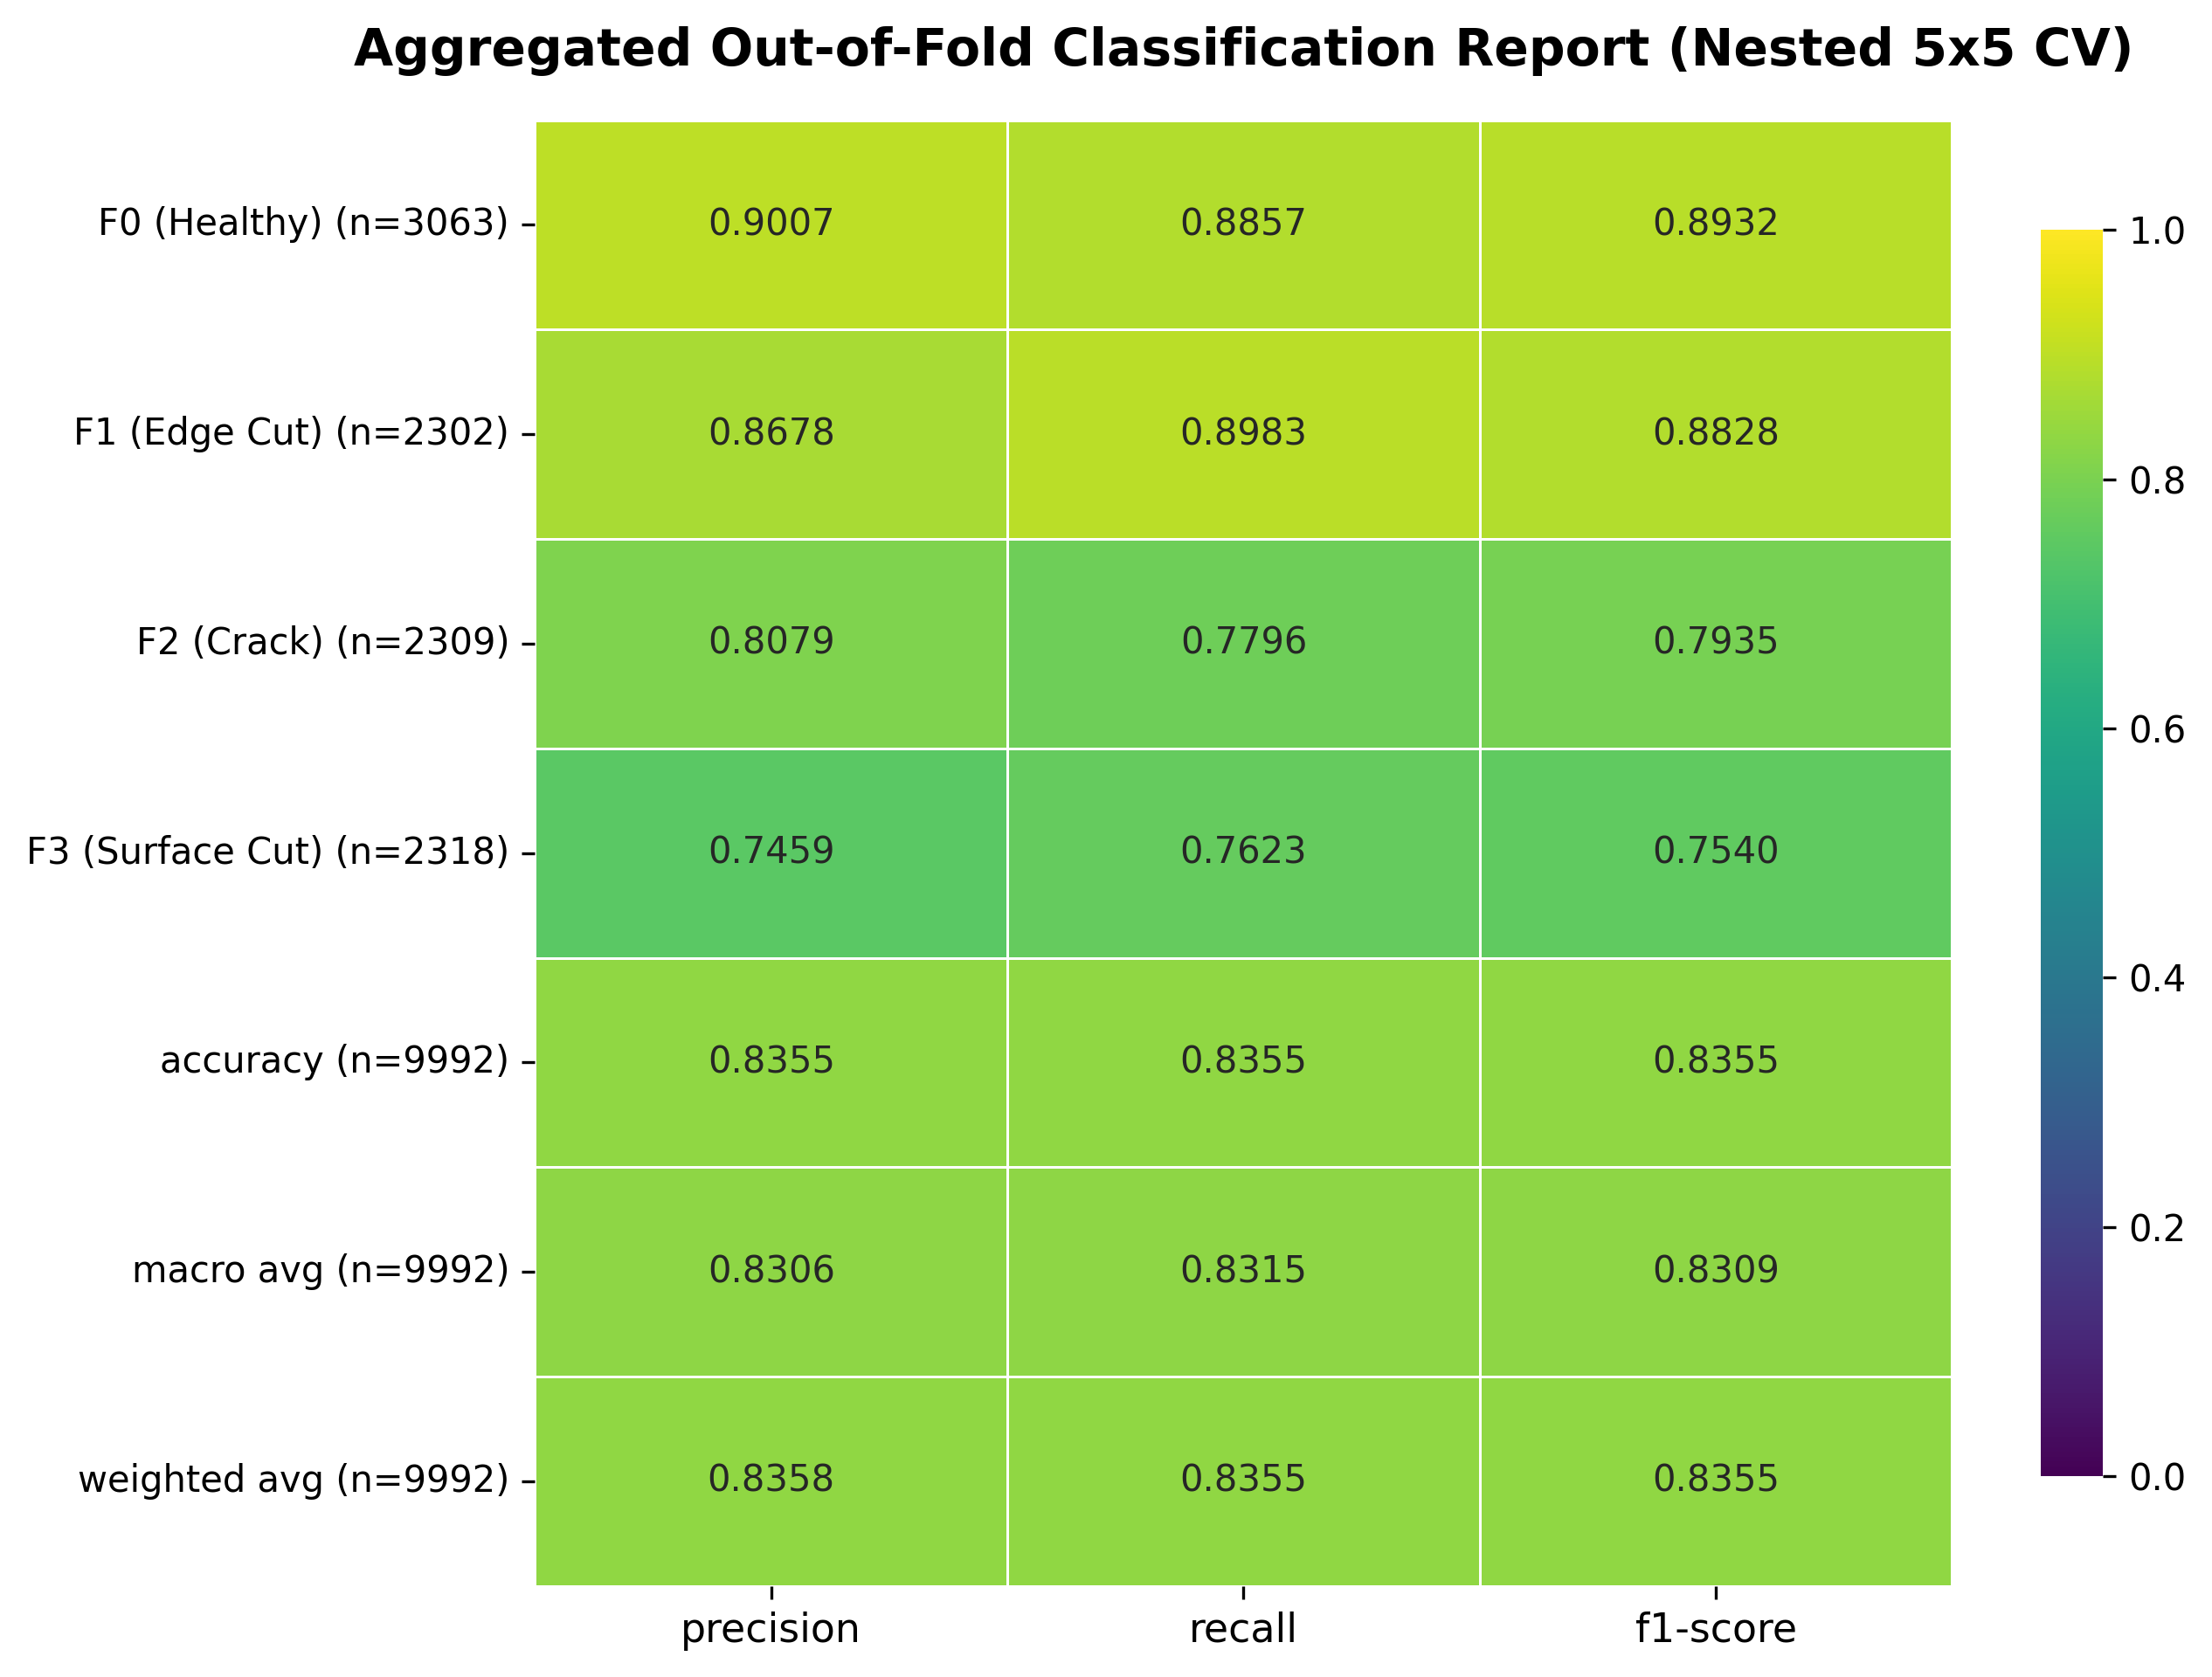

Computing t-SNE on (2103, 256) features from Outer Fold 2 / Inner Fold 2...
Saved t-SNE plot to: nested_cv_tsne_clusters.png


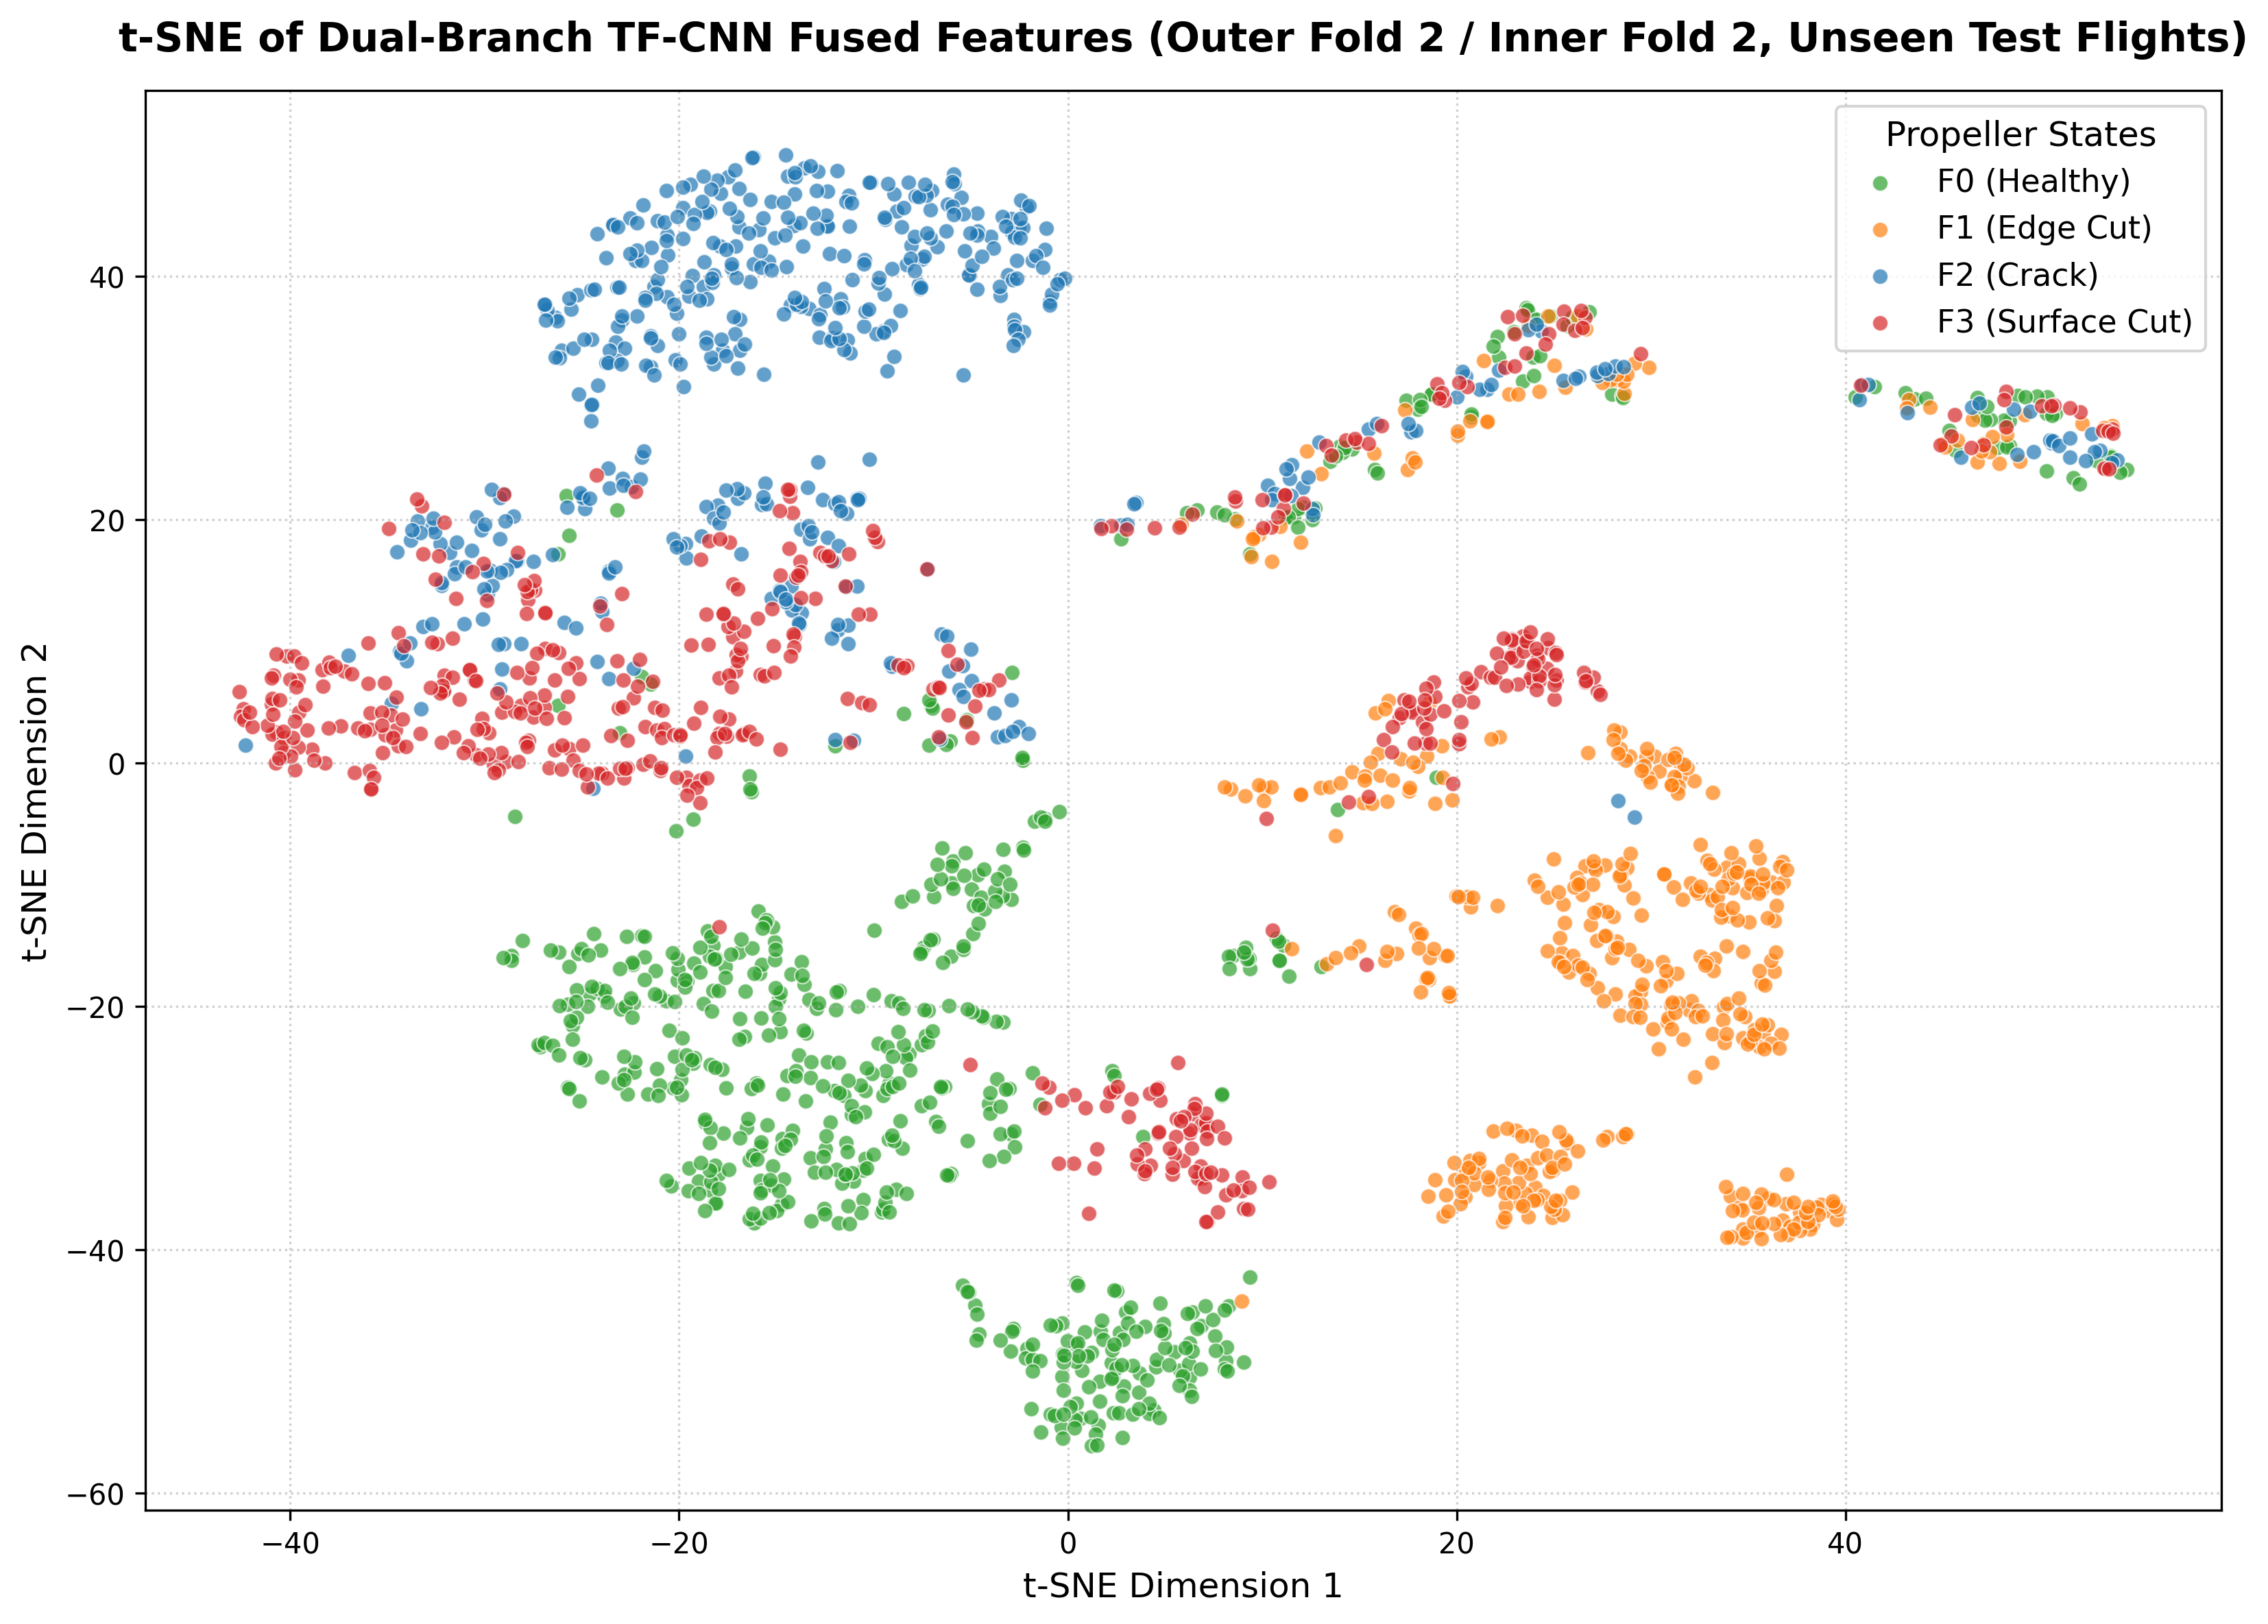

In [3]:
# =============================================================================
# 1. IMPORTS, DEVICE & HYPERPARAMETERS
# =============================================================================
import os
import glob
import copy
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Path to DronePropA .mat files (e.g., "/content/drone_data" on Colab)
drone_dir = r"/content/drone_data"

# Hyperparameters
batch_size = 512
epochs = 50
lr = 0.001
weight_decay = 0.001
window_len = 1000
num_classes = 4
eps = 1e-5

# 13 correlation-pruned channels (0-based indices):
# Acc1 X/Y/Z (29,30,31), Gyro1 Roll/Pitch/Yaw (26,27,28),
# Acc2 X/Y/Z (35,36,37), FL/FR/BL/BR Motor Cmd (46,48,50,52)
target_indices = [29, 30, 31, 26, 27, 28, 35, 36, 37, 46, 48, 50, 52]
class_names = ["F0 (Healthy)", "F1 (Edge Cut)", "F2 (Crack)", "F3 (Surface Cut)"]


# =============================================================================
# 2. PREPROCESSING & FILE-GROUPED LOADING (RUNS ONCE)
# =============================================================================
def generate_time_freq_windows(signal_matrix, window_len=1000):
    """
    Input:  signal_matrix -> (13, N_samples)
    Output: time_windows  -> (num_windows, 13, window_len), float32
            freq_windows  -> (num_windows, 13, window_len), float32
    """
    time_windows = []
    freq_windows = []

    total_samples = signal_matrix.shape[1]
    num_windows = total_samples // window_len

    # Global per-flight mean removal (preserves raw physical vibration amplitude)
    mean = np.mean(signal_matrix, axis=1, keepdims=True)  # (13, 1)
    mean_shift_matrix = signal_matrix - mean              # (13, N_samples)

    for i in range(num_windows):
        k_start = i * window_len
        k_end = (i + 1) * window_len

        time_segment = mean_shift_matrix[:, k_start:k_end].astype(np.float32)
        freq_segment = (np.abs(np.fft.fft(time_segment, axis=1)) / window_len).astype(np.float32)

        time_windows.append(time_segment)
        freq_windows.append(freq_segment)

    return np.array(time_windows), np.array(freq_windows)


def load_files_grouped(data_dir, target_indices, window_len=1000):
    """
    Loads all 130 .mat files once and keeps each flight's windows grouped
    separately so outer and inner CV splits happen strictly at the file level.
    """
    mat_files = sorted(glob.glob(os.path.join(data_dir, "**", "*.mat"), recursive=True))
    assert len(mat_files) > 0, f"No .mat files found in '{data_dir}'."

    file_time_list = []
    file_freq_list = []
    file_labels = []

    for fpath in mat_files:
        basename = os.path.basename(fpath)
        label = int(basename[1])  # F0->0, F1->1, F2->2, F3->3

        mat = sio.loadmat(fpath)
        selected = mat["QDrone_data"][target_indices, :]  # (13, N_samples)

        t_segs, f_segs = generate_time_freq_windows(selected, window_len=window_len)
        file_time_list.append(t_segs)
        file_freq_list.append(f_segs)
        file_labels.append(label)

    file_labels = np.array(file_labels, dtype=np.int64)
    print(f"Loaded {len(file_labels)} files | Class counts [F0, F1, F2, F3]: {np.bincount(file_labels, minlength=num_classes)}")
    return file_time_list, file_freq_list, file_labels


def concat_selected_files(file_indices, file_time_list, file_freq_list, file_labels):
    """Concatenates windows strictly for the given file indices."""
    X_t = np.concatenate([file_time_list[i] for i in file_indices], axis=0)
    X_f = np.concatenate([file_freq_list[i] for i in file_indices], axis=0)
    y = np.concatenate([
        np.full(len(file_time_list[i]), file_labels[i], dtype=np.int64)
        for i in file_indices
    ], axis=0)
    return X_t, X_f, y


class DroneTFDataset(Dataset):
    def __init__(self, X_t, X_f, y):
        self.X_t = torch.from_numpy(X_t).float()
        self.X_f = torch.from_numpy(X_f).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_t[idx], self.X_f[idx], self.y[idx]


# =============================================================================
# 3. DUAL-BRANCH TF-CNN (CAUSAL CONV + bias=True + LAYERNORM + NATIVE GAP)
# =============================================================================
class CausalConv1d(nn.Module):
    """
    Strictly causal 1D convolution with bias=True.
    Left-pads by (kernel_size - 1) * dilation so timestep t only sees <= t.
    Shape: (B, C_in, L) -> (B, C_out, L)
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1, bias=True):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            padding=0,
            dilation=dilation,
            bias=bias
        )

    def forward(self, x):
        x = F.pad(x, (self.left_pad, 0))  # (B, C_in, L + left_pad)
        return self.conv(x)               # (B, C_out, L)


class ChannelLayerNorm(nn.Module):
    """
    LayerNorm across channels C at each timestep/frequency bin independently.
    Preserves causality (zero lookahead across L) and avoids cross-flight batch stats.
    Shape: (B, C, L) -> (B, L, C) -> LayerNorm(C) -> (B, C, L)
    """
    def __init__(self, num_channels, eps=1e-5):
        super().__init__()
        self.norm = nn.LayerNorm(num_channels, eps=eps)

    def forward(self, x):
        x = x.transpose(1, 2)             # (B, L, C)
        x = self.norm(x)                  # (B, L, C)
        return x.transpose(1, 2)          # (B, C, L)


class GlobalAvgPool1d(nn.Module):
    """Native Global Average Pooling via torch.mean: (B, C, L) -> (B, C, 1)"""
    def forward(self, x):
        return torch.mean(x, dim=-1, keepdim=True)


class DualBranchTFCNN(nn.Module):
    def __init__(self, in_channels=13, num_classes=4, eps=1e-5):
        super().__init__()

        # Causal Time-Domain Branch: (B, 13, 1000) -> (B, 128, 1)
        self.time_branch = nn.Sequential(
            CausalConv1d(in_channels, 32, kernel_size=7, dilation=1, bias=True),  # (B, 32, 1000)
            ChannelLayerNorm(32, eps=eps),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),                                          # (B, 32, 500)

            CausalConv1d(32, 64, kernel_size=5, dilation=2, bias=True),           # (B, 64, 500)
            ChannelLayerNorm(64, eps=eps),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),                                          # (B, 64, 250)

            CausalConv1d(64, 128, kernel_size=3, dilation=4, bias=True),          # (B, 128, 250)
            ChannelLayerNorm(128, eps=eps),
            nn.ReLU(),
            GlobalAvgPool1d()                                                     # (B, 128, 1)
        )

        # Symmetric Frequency-Domain Branch: (B, 13, 1000) -> (B, 128, 1)
        self.freq_branch = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=7, padding=3, bias=True),      # (B, 32, 1000)
            ChannelLayerNorm(32, eps=eps),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),                                          # (B, 32, 500)

            nn.Conv1d(32, 64, kernel_size=5, padding=2, bias=True),               # (B, 64, 500)
            ChannelLayerNorm(64, eps=eps),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),                                          # (B, 64, 250)

            nn.Conv1d(64, 128, kernel_size=3, padding=1, bias=True),              # (B, 128, 250)
            ChannelLayerNorm(128, eps=eps),
            nn.ReLU(),
            GlobalAvgPool1d()                                                     # (B, 128, 1)
        )

        # Fusion & Classification Head: (B, 256) -> (B, num_classes)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128, bias=True),
            nn.LayerNorm(128, eps=eps),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes, bias=True)
        )

    def extract_features(self, t_x, f_x):
        t_feat = self.time_branch(t_x).squeeze(-1)  # (B, 128)
        f_feat = self.freq_branch(f_x).squeeze(-1)  # (B, 128)
        return torch.cat((t_feat, f_feat), dim=1)   # (B, 256)

    def forward(self, t_x, f_x):
        fused = self.extract_features(t_x, f_x)     # (B, 256)
        return self.classifier(fused)               # (B, num_classes)


# =============================================================================
# 4. NESTED 5x5 STRATIFIED CROSS-VALIDATION (104/26 OUTER, ~83/~21 INNER)
# =============================================================================
def run_nested_5x5_cv(
    file_time_list,
    file_freq_list,
    file_labels,
    model_fn,
    batch_size=512,
    epochs=50,
    lr=0.001,
    weight_decay=0.001,
    num_classes=4,
    device=device
):
    outer_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    all_file_idx = np.arange(len(file_labels))
    pin_mem = (device.type == "cuda")

    seen_outer_test_files = set()
    outer_ensemble_accs = []
    outer_mean_inner_accs = []
    oof_true = []
    oof_preds = []

    # Epoch curves across all 25 runs: shape (25, epochs)
    history = {
        "train_loss": np.zeros((25, epochs), dtype=np.float64),
        "val_loss":   np.zeros((25, epochs), dtype=np.float64),
        "train_acc":  np.zeros((25, epochs), dtype=np.float64),
        "val_acc":    np.zeros((25, epochs), dtype=np.float64),
    }

    # Tracks single best-validation model's unseen outer-test features for clean t-SNE
    best_overall_val_loss = float("inf")
    tsne_bundle = {"features": None, "targets": None, "tag": ""}

    # --- OUTER 5-FOLD LOOP (104 dev / 26 unseen test) ---
    for outer_fold, (dev_idx, test_idx) in enumerate(outer_skf.split(all_file_idx, file_labels), start=1):
        assert seen_outer_test_files.isdisjoint(test_idx), "Outer test files repeated across folds!"
        seen_outer_test_files.update(test_idx)

        print(f"\n{'#'*72}")
        print(f"OUTER FOLD {outer_fold}/5 | Dev: {len(dev_idx)} files {np.bincount(file_labels[dev_idx], minlength=num_classes)} "
              f"| Test: {len(test_idx)} files {np.bincount(file_labels[test_idx], minlength=num_classes)}")
        print(f"{'#'*72}")

        X_t_test, X_f_test, y_test = concat_selected_files(test_idx, file_time_list, file_freq_list, file_labels)
        test_loader = DataLoader(
            DroneTFDataset(X_t_test, X_f_test, y_test),
            batch_size=batch_size, shuffle=False, pin_memory=pin_mem
        )

        outer_test_probs_sum = np.zeros((len(y_test), num_classes), dtype=np.float64)
        inner_val_accs = []
        inner_test_accs = []

        # --- INNER 5-FOLD LOOP (Inside the 104 dev files -> ~83 train / ~21 val) ---
        inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + outer_fold)
        seen_inner_val_files = set()

        for inner_fold, (inner_train_pos, inner_val_pos) in enumerate(
            inner_skf.split(dev_idx, file_labels[dev_idx]), start=1
        ):
            run_idx = (outer_fold - 1) * 5 + (inner_fold - 1)  # 0..24

            # Map relative positions (0..103) back to global file indices (0..129)
            train_idx = dev_idx[inner_train_pos]
            val_idx = dev_idx[inner_val_pos]

            # Zero-leakage assertions
            assert set(train_idx).isdisjoint(val_idx)
            assert set(train_idx).isdisjoint(test_idx)
            assert set(val_idx).isdisjoint(test_idx)
            assert seen_inner_val_files.isdisjoint(val_idx)
            seen_inner_val_files.update(val_idx)

            print(f"\n  [Outer {outer_fold} | Inner {inner_fold}/5 | Run {run_idx + 1}/25] "
                  f"Train: {len(train_idx)} files {np.bincount(file_labels[train_idx], minlength=num_classes)} | "
                  f"Val: {len(val_idx)} files {np.bincount(file_labels[val_idx], minlength=num_classes)}")

            X_t_train, X_f_train, y_train = concat_selected_files(train_idx, file_time_list, file_freq_list, file_labels)
            X_t_val, X_f_val, y_val = concat_selected_files(val_idx, file_time_list, file_freq_list, file_labels)

            train_loader = DataLoader(
                DroneTFDataset(X_t_train, X_f_train, y_train),
                batch_size=batch_size, shuffle=True, pin_memory=pin_mem
            )
            val_loader = DataLoader(
                DroneTFDataset(X_t_val, X_f_val, y_val),
                batch_size=batch_size, shuffle=False, pin_memory=pin_mem
            )

            torch.manual_seed(42 + run_idx)
            model = model_fn().to(device)
            criterion = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

            best_val_loss = float("inf")
            best_val_acc = 0.0
            best_weights = copy.deepcopy(model.state_dict())

            # --- Train & Validate ---
            for epoch in range(epochs):
                model.train()
                t_loss_sum = 0.0
                t_correct = 0

                for t_in, f_in, targets in train_loader:
                    t_in = t_in.to(device, non_blocking=pin_mem)
                    f_in = f_in.to(device, non_blocking=pin_mem)
                    targets = targets.to(device, non_blocking=pin_mem)

                    optimizer.zero_grad()
                    logits = model(t_in, f_in)
                    loss = criterion(logits, targets)
                    loss.backward()
                    optimizer.step()

                    t_loss_sum += loss.item() * targets.size(0)
                    t_correct += (logits.argmax(dim=1) == targets).sum().item()

                train_loss = t_loss_sum / len(train_loader.dataset)
                train_acc = t_correct / len(train_loader.dataset)

                model.eval()
                v_loss_sum = 0.0
                v_correct = 0

                with torch.no_grad():
                    for t_in, f_in, targets in val_loader:
                        t_in = t_in.to(device, non_blocking=pin_mem)
                        f_in = f_in.to(device, non_blocking=pin_mem)
                        targets = targets.to(device, non_blocking=pin_mem)

                        logits = model(t_in, f_in)
                        loss = criterion(logits, targets)

                        v_loss_sum += loss.item() * targets.size(0)
                        v_correct += (logits.argmax(dim=1) == targets).sum().item()

                val_loss = v_loss_sum / len(val_loader.dataset)
                val_acc = v_correct / len(val_loader.dataset)

                history["train_loss"][run_idx, epoch] = train_loss
                history["val_loss"][run_idx, epoch] = val_loss
                history["train_acc"][run_idx, epoch] = train_acc
                history["val_acc"][run_idx, epoch] = val_acc

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_val_acc = val_acc
                    best_weights = copy.deepcopy(model.state_dict())

            inner_val_accs.append(best_val_acc)

            # --- Evaluate Best Checkpoint on Outer 26 Unseen Test Files ---
            model.load_state_dict(best_weights)
            model.eval()
            probs_list = []
            capture_tsne = (best_val_loss < best_overall_val_loss)
            feats_list = []

            with torch.no_grad():
                for t_in, f_in, _ in test_loader:
                    t_in = t_in.to(device, non_blocking=pin_mem)
                    f_in = f_in.to(device, non_blocking=pin_mem)

                    fused = model.extract_features(t_in, f_in)  # (B, 256)
                    logits = model.classifier(fused)            # (B, 4)
                    probs_list.append(F.softmax(logits, dim=1).cpu().numpy())

                    if capture_tsne:
                        feats_list.append(fused.cpu().numpy())

            if capture_tsne:
                best_overall_val_loss = best_val_loss
                tsne_bundle["features"] = np.concatenate(feats_list, axis=0)
                tsne_bundle["targets"] = y_test.copy()
                tsne_bundle["tag"] = f"Outer Fold {outer_fold} / Inner Fold {inner_fold}"

            inner_test_probs = np.concatenate(probs_list, axis=0)
            inner_test_acc = accuracy_score(y_test, inner_test_probs.argmax(axis=1))
            inner_test_accs.append(inner_test_acc)
            outer_test_probs_sum += inner_test_probs

            print(f"    -> Best Val Loss: {best_val_loss:.4f} | Best Val Acc: {best_val_acc*100:.2f}% "
                  f"| Outer Test Acc: {inner_test_acc*100:.2f}%")

            del model, optimizer, train_loader, val_loader
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        assert len(seen_inner_val_files) == len(dev_idx)

        outer_preds = outer_test_probs_sum.argmax(axis=1)
        outer_ens_acc = accuracy_score(y_test, outer_preds)
        outer_mean_acc = float(np.mean(inner_test_accs))

        outer_ensemble_accs.append(outer_ens_acc)
        outer_mean_inner_accs.append(outer_mean_acc)
        oof_true.extend(y_test)
        oof_preds.extend(outer_preds)

        print(f"\n>>> OUTER FOLD {outer_fold} SUMMARY:")
        print(f"    Inner Val Accs:         {[round(a*100, 2) for a in inner_val_accs]} (Mean: {np.mean(inner_val_accs)*100:.2f}%)")
        print(f"    Mean Single-Model Test: {outer_mean_acc*100:.2f}% +/- {np.std(inner_test_accs)*100:.2f}%")
        print(f"    5-Model Ensemble Test:  {outer_ens_acc*100:.2f}%")

        del test_loader

    assert len(seen_outer_test_files) == len(file_labels)

    outer_mean_inner_accs = np.array(outer_mean_inner_accs)
    outer_ensemble_accs = np.array(outer_ensemble_accs)

    print(f"\n{'='*72}")
    print(f"FINAL NESTED 5x5 CV RESULTS (All {len(seen_outer_test_files)} unique flights tested once)")
    print(f"Per-Fold Mean Single-Model Test Acc: {[round(a*100, 2) for a in outer_mean_inner_accs]}")
    print(f"Overall Single-Model Test Acc:       {outer_mean_inner_accs.mean()*100:.2f}% +/- {outer_mean_inner_accs.std()*100:.2f}%")
    print(f"Per-Fold 5-Model Ensemble Test Acc:  {[round(a*100, 2) for a in outer_ensemble_accs]}")
    print(f"Overall 5-Model Ensemble Test Acc:   {outer_ensemble_accs.mean()*100:.2f}% +/- {outer_ensemble_accs.std()*100:.2f}%")
    print(f"{'='*72}")

    return outer_mean_inner_accs, outer_ensemble_accs, np.array(oof_true), np.array(oof_preds), history, tsne_bundle


# =============================================================================
# 5. VISUALIZATION FUNCTIONS (CURVES, CONFUSION MATRIX, REPORT, t-SNE)
# =============================================================================
def plot_learning_curves(history, save_path="nested_cv_learning_curves.png"):
    """Plots Mean +/- 1 Std Training & Validation Loss and Accuracy across all 25 runs."""
    epochs_axis = np.arange(1, history["train_loss"].shape[1] + 1)

    t_loss_mean, t_loss_std = history["train_loss"].mean(axis=0), history["train_loss"].std(axis=0)
    v_loss_mean, v_loss_std = history["val_loss"].mean(axis=0),   history["val_loss"].std(axis=0)
    t_acc_mean,  t_acc_std  = history["train_acc"].mean(axis=0) * 100, history["train_acc"].std(axis=0) * 100
    v_acc_mean,  v_acc_std  = history["val_acc"].mean(axis=0) * 100,   history["val_acc"].std(axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=300)

    # Loss subplot
    axes[0].plot(epochs_axis, t_loss_mean, color="#1f77b4", linewidth=2.2, label="Training Loss (Mean)")
    axes[0].fill_between(epochs_axis, t_loss_mean - t_loss_std, t_loss_mean + t_loss_std,
                         color="#1f77b4", alpha=0.2, label="Train ± 1 Std")
    axes[0].plot(epochs_axis, v_loss_mean, color="#d62728", linewidth=2.2, label="Validation Loss (Mean)")
    axes[0].fill_between(epochs_axis, v_loss_mean - v_loss_std, v_loss_mean + v_loss_std,
                         color="#d62728", alpha=0.2, label="Val ± 1 Std")
    axes[0].set_title("Training vs Validation Loss (Nested 5x5 CV)", fontsize=14, fontweight="bold", pad=12)
    axes[0].set_xlabel("Epoch", fontsize=12)
    axes[0].set_ylabel("Cross-Entropy Loss", fontsize=12)
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend(fontsize=10)

    # Accuracy subplot
    axes[1].plot(epochs_axis, t_acc_mean, color="#2ca02c", linewidth=2.2, label="Training Accuracy (Mean)")
    axes[1].fill_between(epochs_axis,
                         np.clip(t_acc_mean - t_acc_std, 0, 100),
                         np.clip(t_acc_mean + t_acc_std, 0, 100),
                         color="#2ca02c", alpha=0.2, label="Train ± 1 Std")
    axes[1].plot(epochs_axis, v_acc_mean, color="#ff7f0e", linewidth=2.2, label="Validation Accuracy (Mean)")
    axes[1].fill_between(epochs_axis,
                         np.clip(v_acc_mean - v_acc_std, 0, 100),
                         np.clip(v_acc_mean + v_acc_std, 0, 100),
                         color="#ff7f0e", alpha=0.2, label="Val ± 1 Std")
    axes[1].set_title("Training vs Validation Accuracy (Nested 5x5 CV)", fontsize=14, fontweight="bold", pad=12)
    axes[1].set_xlabel("Epoch", fontsize=12)
    axes[1].set_ylabel("Accuracy (%)", fontsize=12)
    axes[1].set_ylim(0, 102)
    axes[1].grid(True, linestyle=":", alpha=0.6)
    axes[1].legend(loc="lower right", fontsize=10)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved learning curves to: {save_path}")
    plt.show()


def plot_colorful_metrics(
    y_true,
    y_pred,
    class_names,
    cm_path="nested_cv_confusion_matrix.png",
    cr_path="nested_cv_classification_report.png"
):
    # 1. Colorful Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6.5), dpi=300)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        square=True,
        linewidths=0.6,
        cbar_kws={"shrink": 0.8}
    )
    plt.title("Aggregated Out-of-Fold Confusion Matrix (Nested 5x5 CV)", fontsize=14, fontweight="bold", pad=15)
    plt.xlabel("Predicted Fault Class", fontsize=12)
    plt.ylabel("True Fault Class", fontsize=12)
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {cm_path}")
    plt.show()

    # 2. Colorful Classification Report Heatmap
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()

    supports = df_report["support"].copy()
    df_metrics = df_report.drop("support", axis=1)
    y_labels = [
        f"{row} (n={int(supports[row])})" if row != "accuracy" else f"accuracy (n={len(y_true)})"
        for row in df_metrics.index
    ]

    plt.figure(figsize=(9, 6.5), dpi=300)
    sns.heatmap(
        df_metrics,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
        yticklabels=y_labels,
        linewidths=0.6,
        cbar_kws={"shrink": 0.85}
    )
    plt.title("Aggregated Out-of-Fold Classification Report (Nested 5x5 CV)", fontsize=14, fontweight="bold", pad=15)
    plt.xticks(fontsize=11)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.savefig(cr_path, dpi=300, bbox_inches="tight")
    print(f"Saved classification report to: {cr_path}")
    plt.show()


def plot_tsne_from_bundle(tsne_bundle, class_names, save_path="nested_cv_tsne_clusters.png"):
    """Plots 2D t-SNE of fused 256-d unseen test features from one consistent latent space."""
    features = tsne_bundle["features"]
    targets = tsne_bundle["targets"]
    tag = tsne_bundle["tag"]

    print(f"Computing t-SNE on {features.shape} features from {tag}...")
    tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, init="pca", learning_rate="auto", random_state=42)
    features_2d = tsne.fit_transform(features)

    colors = ["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728"]

    plt.figure(figsize=(11, 8), dpi=300)
    for class_idx, (class_name, color) in enumerate(zip(class_names, colors)):
        mask = (targets == class_idx)
        plt.scatter(
            features_2d[mask, 0],
            features_2d[mask, 1],
            c=color,
            label=class_name,
            alpha=0.7,
            edgecolors="w",
            linewidth=0.5,
            s=30
        )

    plt.title(f"t-SNE of Dual-Branch TF-CNN Fused Features ({tag}, Unseen Test Flights)",
              fontsize=14, fontweight="bold", pad=14)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.legend(title="Propeller States", title_fontsize=12, fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved t-SNE plot to: {save_path}")
    plt.show()


# =============================================================================
# 6. EXECUTE FULL PIPELINE
# =============================================================================
file_time_list, file_freq_list, file_labels = load_files_grouped(
    data_dir=drone_dir,
    target_indices=target_indices,
    window_len=window_len
)

mean_single_accs, ensemble_accs, y_true_oof, y_pred_oof, history, tsne_bundle = run_nested_5x5_cv(
    file_time_list=file_time_list,
    file_freq_list=file_freq_list,
    file_labels=file_labels,
    model_fn=lambda: DualBranchTFCNN(in_channels=len(target_indices), num_classes=num_classes, eps=eps),
    batch_size=batch_size,
    epochs=epochs,
    lr=lr,
    weight_decay=weight_decay,
    num_classes=num_classes,
    device=device
)

# Generate & save all 4 figures (300 DPI)
plot_learning_curves(history, save_path="nested_cv_learning_curves.png")
plot_colorful_metrics(
    y_true_oof,
    y_pred_oof,
    class_names=class_names,
    cm_path="nested_cv_confusion_matrix.png",
    cr_path="nested_cv_classification_report.png"
)
plot_tsne_from_bundle(tsne_bundle, class_names=class_names, save_path="nested_cv_tsne_clusters.png")